# Classic Literature Recommendation System

## 1. Data Scraping

To prevent the classic Topic Drift issue of unconstrained breadth-first web crawling (e.g., Kafka $\to$ Prague $\to$ Austro-Hungarian Empire $\to$ World War I $\to$ Tanks), data collection was executed in three targeted phases:

* **Phase 1 - Curated Award Lists:** Extracted canonical book and author links from three major literature collections:
    - Le Monde's 100 Books of the Century
    - Nobel Prize in Literature Laureates
    - Pulitzer Prize for Fiction Winners

* **Phase 2 - Author Expansion:** Iterated through authors from Phase 1 and extracted links to their 'Notable works'

* **Phase 3 - Final Scraping:** Scraped all the collected links and saved data to 'JSON Lines (.jsonl)' file

## 2. Preprocessing

* **Phase 1 - Cleaning & Domain Stopwords:** Normalized text to lowercase, removed non-alphabetic characters, and pruned both standard English stopwords and domain-specific publishing noise (isbn, oclc, press, edition, publisher, published, volume, retrieved).

* **Phase 2 - Stemming:** Applied nltk.PorterStemmer to strip suffixes via heuristic rules

* **Phase 3 - Lemmatization:** Applied nltk.WordNetLemmatizer to reduce tokens to valid morphological base forms

* **Design Decision:** Lemmatized text was selected as the primary representation for sparse modeling because it preserves valid vocabulary necessary for interpretable prediction breakdowns.

* **Storage:** Filtered out stubs ($< 300$ characters) and stored the final corpus ($\ge 1000$ documents) in Parquet format (.parquet)

## 3. Similarities

* **Phase 1 - Sparse TF-IDF Index:** Fitted a TfidfVectorizer (max 5,000 features, document frequency bounds: $\text{min\_df}=2, \text{max\_df}=0.8$) over the lemmatized corpus.

* **Phase 2 - Dense Semantic Embeddings:** Generated 384-dimensional dense vectors from lead summaries using the pre-trained sentence-transformers/all-MiniLM-L6-v2 model

* **Phase 3 - User Profile Representation:** For a user query consisting of $K$ visited articles $\mathcal{A}_{\text{visited}} = \{a_1, a_2, \dots, a_K\}$, the composite user profile is computed as the centroid of visited vectors:
$$\vec{u}_{\text{dense}} = \frac{1}{K} \sum_{i=1}^K \vec{v}_{a_i}, \quad \hat{u}_{\text{dense}} = \frac{\vec{u}_{\text{dense}}}{\Vert{}\vec{u}_{\text{dense}}\Vert{}_2}$$
$$\vec{u}_{\text{tfidf}} = \frac{1}{K} \sum_{i=1}^K \vec{w}_{a_i}$$

* **Phase 4 - Similarity Metrics:** 
    - Dense Semantic Similarity ($S_{\text{dense}}$): Cosine similarity between normalized profile and article embeddings:$$S_{\text{dense}}(d) = \hat{u}_{\text{dense}} \cdot \hat{v}_d$$
    - Sparse Lexical Similarity ($S_{\text{tfidf}}$): Cosine similarity over TF-IDF vectors:$$S_{\text{tfidf}}(d) = \frac{\vec{u}_{\text{tfidf}} \cdot \vec{w}_d}{\Vert{}\vec{u}_{\text{tfidf}}\Vert{}_2 \Vert{}\vec{w}_d\Vert{}_2}$$

* **Phase 5 - Hybrid Calibration & Scoring:** Because sparse TF-IDF distributions have higher variance and sparsity than dense cosine similarities, both score vectors are Min-Max calibrated across candidate documents before linear combination:
$$\tilde{S}(d) = \frac{S(d) - \min(S)}{\max(S) - \min(S)}$$
$$S_{\text{final}}(d) = \alpha \cdot \tilde{S}_{\text{dense}}(d) + (1 - \alpha) \cdot \tilde{S}_{\text{tfidf}}(d)$$
Where $\alpha = 0.70$ prioritizes latent thematic alignment while retaining lexical precision for named entities.

* **Phase 6 - Dynamic Inference on Unseen Links:** When a user inputs a Wikipedia URL outside the database:
    - The page is scraped and cleaned dynamically.
    - The summary is embedded via all-MiniLM-L6-v2.
    - The body is transformed through the pre-fitted vocabulary using tfidf.transform() (preventing data leakage without re-fitting IDF weights).
    - The generated vector is compared directly against the indexed database.

## 4. Corpus Statistics

In [ ]:
from literature_recommender import LiteratureRecommender, RecommendationVisualizer

recommender = LiteratureRecommender(load_precomputed=True)
visualizer = RecommendationVisualizer(recommender)

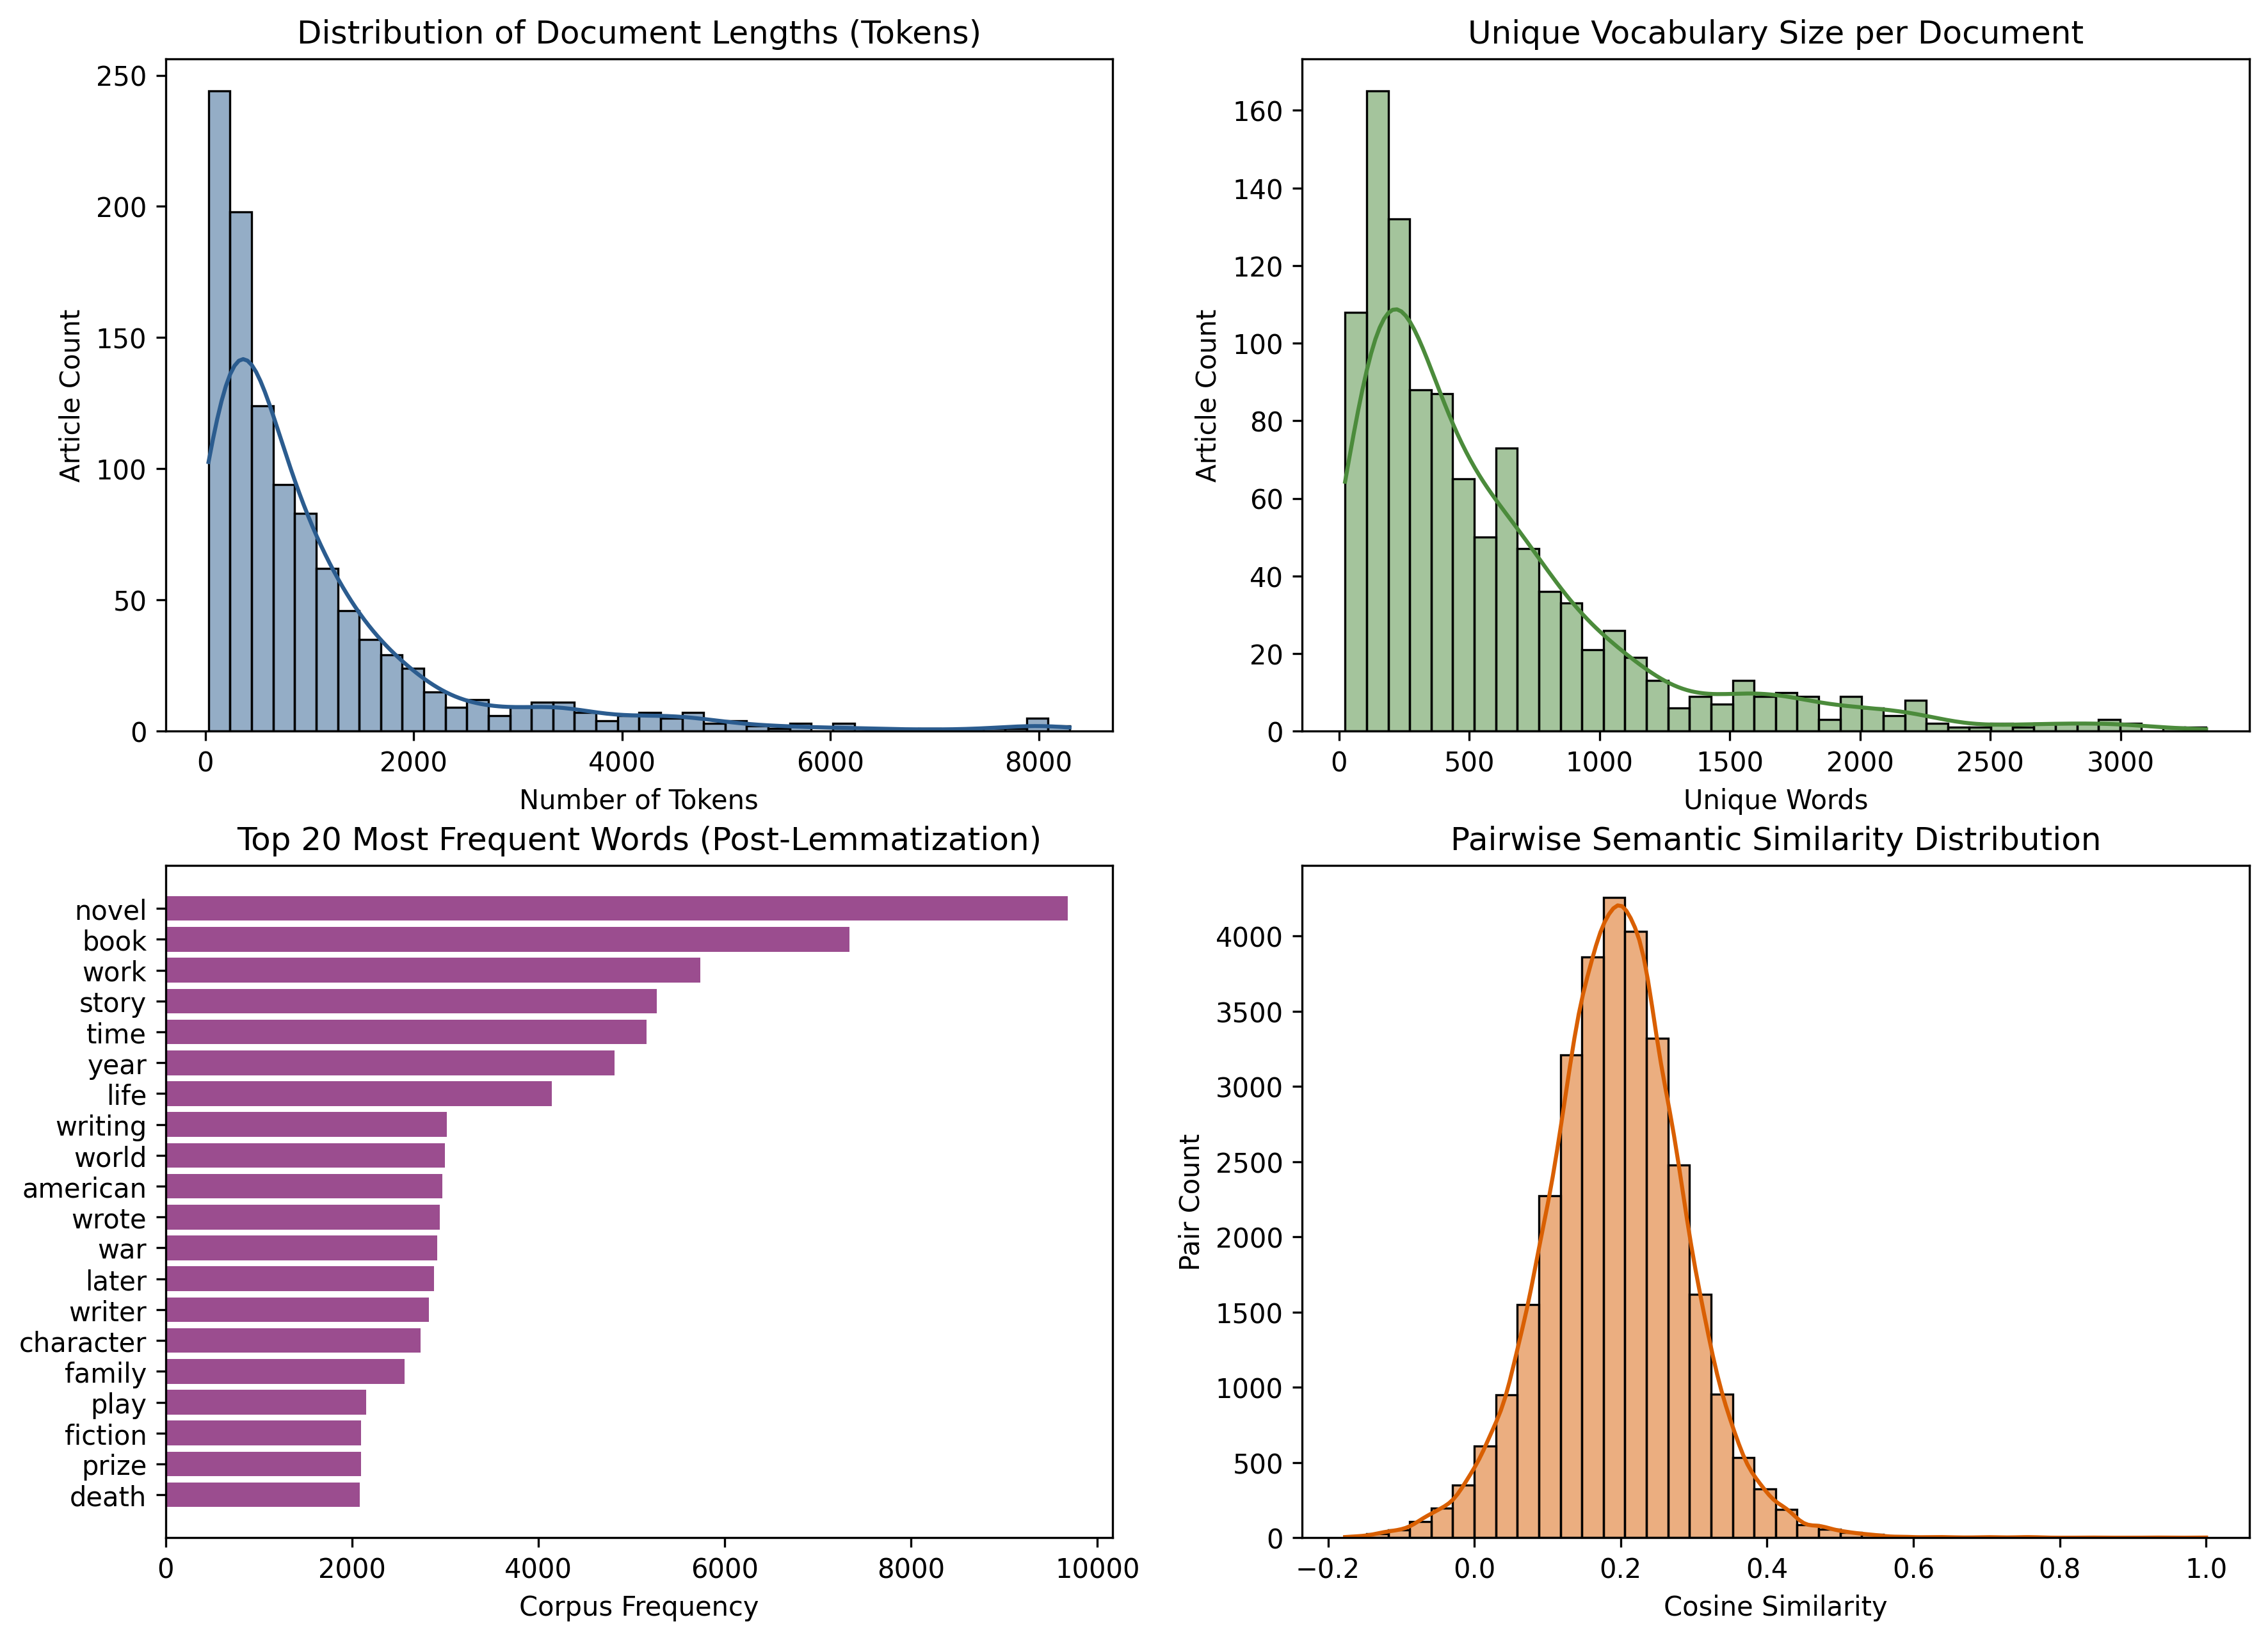

In [ ]:
visualizer.plot_corpus_statistics()

* **Document Length Distribution:** Follows a right-skewed, log-normal distribution. Filtering articles below 300 characters successfully removed incomplete stubs, yielding an average document length suitable for vector space modeling.Vocabulary 

* **Size per Document:** Peaks between 200 and 500 unique lemmatized words per article, with comprehensive author biographies extending beyond 2,000 unique lemmas.Top 20 

* **Lemmatized Words:** Dominated by domain-defining terminology: novel, book, work, story, writing, and character. This confirms topic purity across the crawl. While frequent in absolute counts, IDF naturally downweights these universal terms during retrieval.

* **Pairwise Semantic Similarity Distribution:** Normal distribution centered at $\mu \approx 0.20$ ($\sigma \approx 0.10$). In an unconstrained Wikipedia crawl, pairwise similarity hovers near $0.05$. This positive baseline shift validates domain cohesion across the literature corpus.

## 5. Visual Recommendation Breakdowns

### **Word-Level Prediction Breakdown:**

The contribution of each individual word $w$ to the sparse similarity between a query $q$ and recommendation $r$ is derived from their vector element-wise product:
$$\text{Contribution}(w) = \vec{w}_q[w] \times \vec{w}_r[w]$$

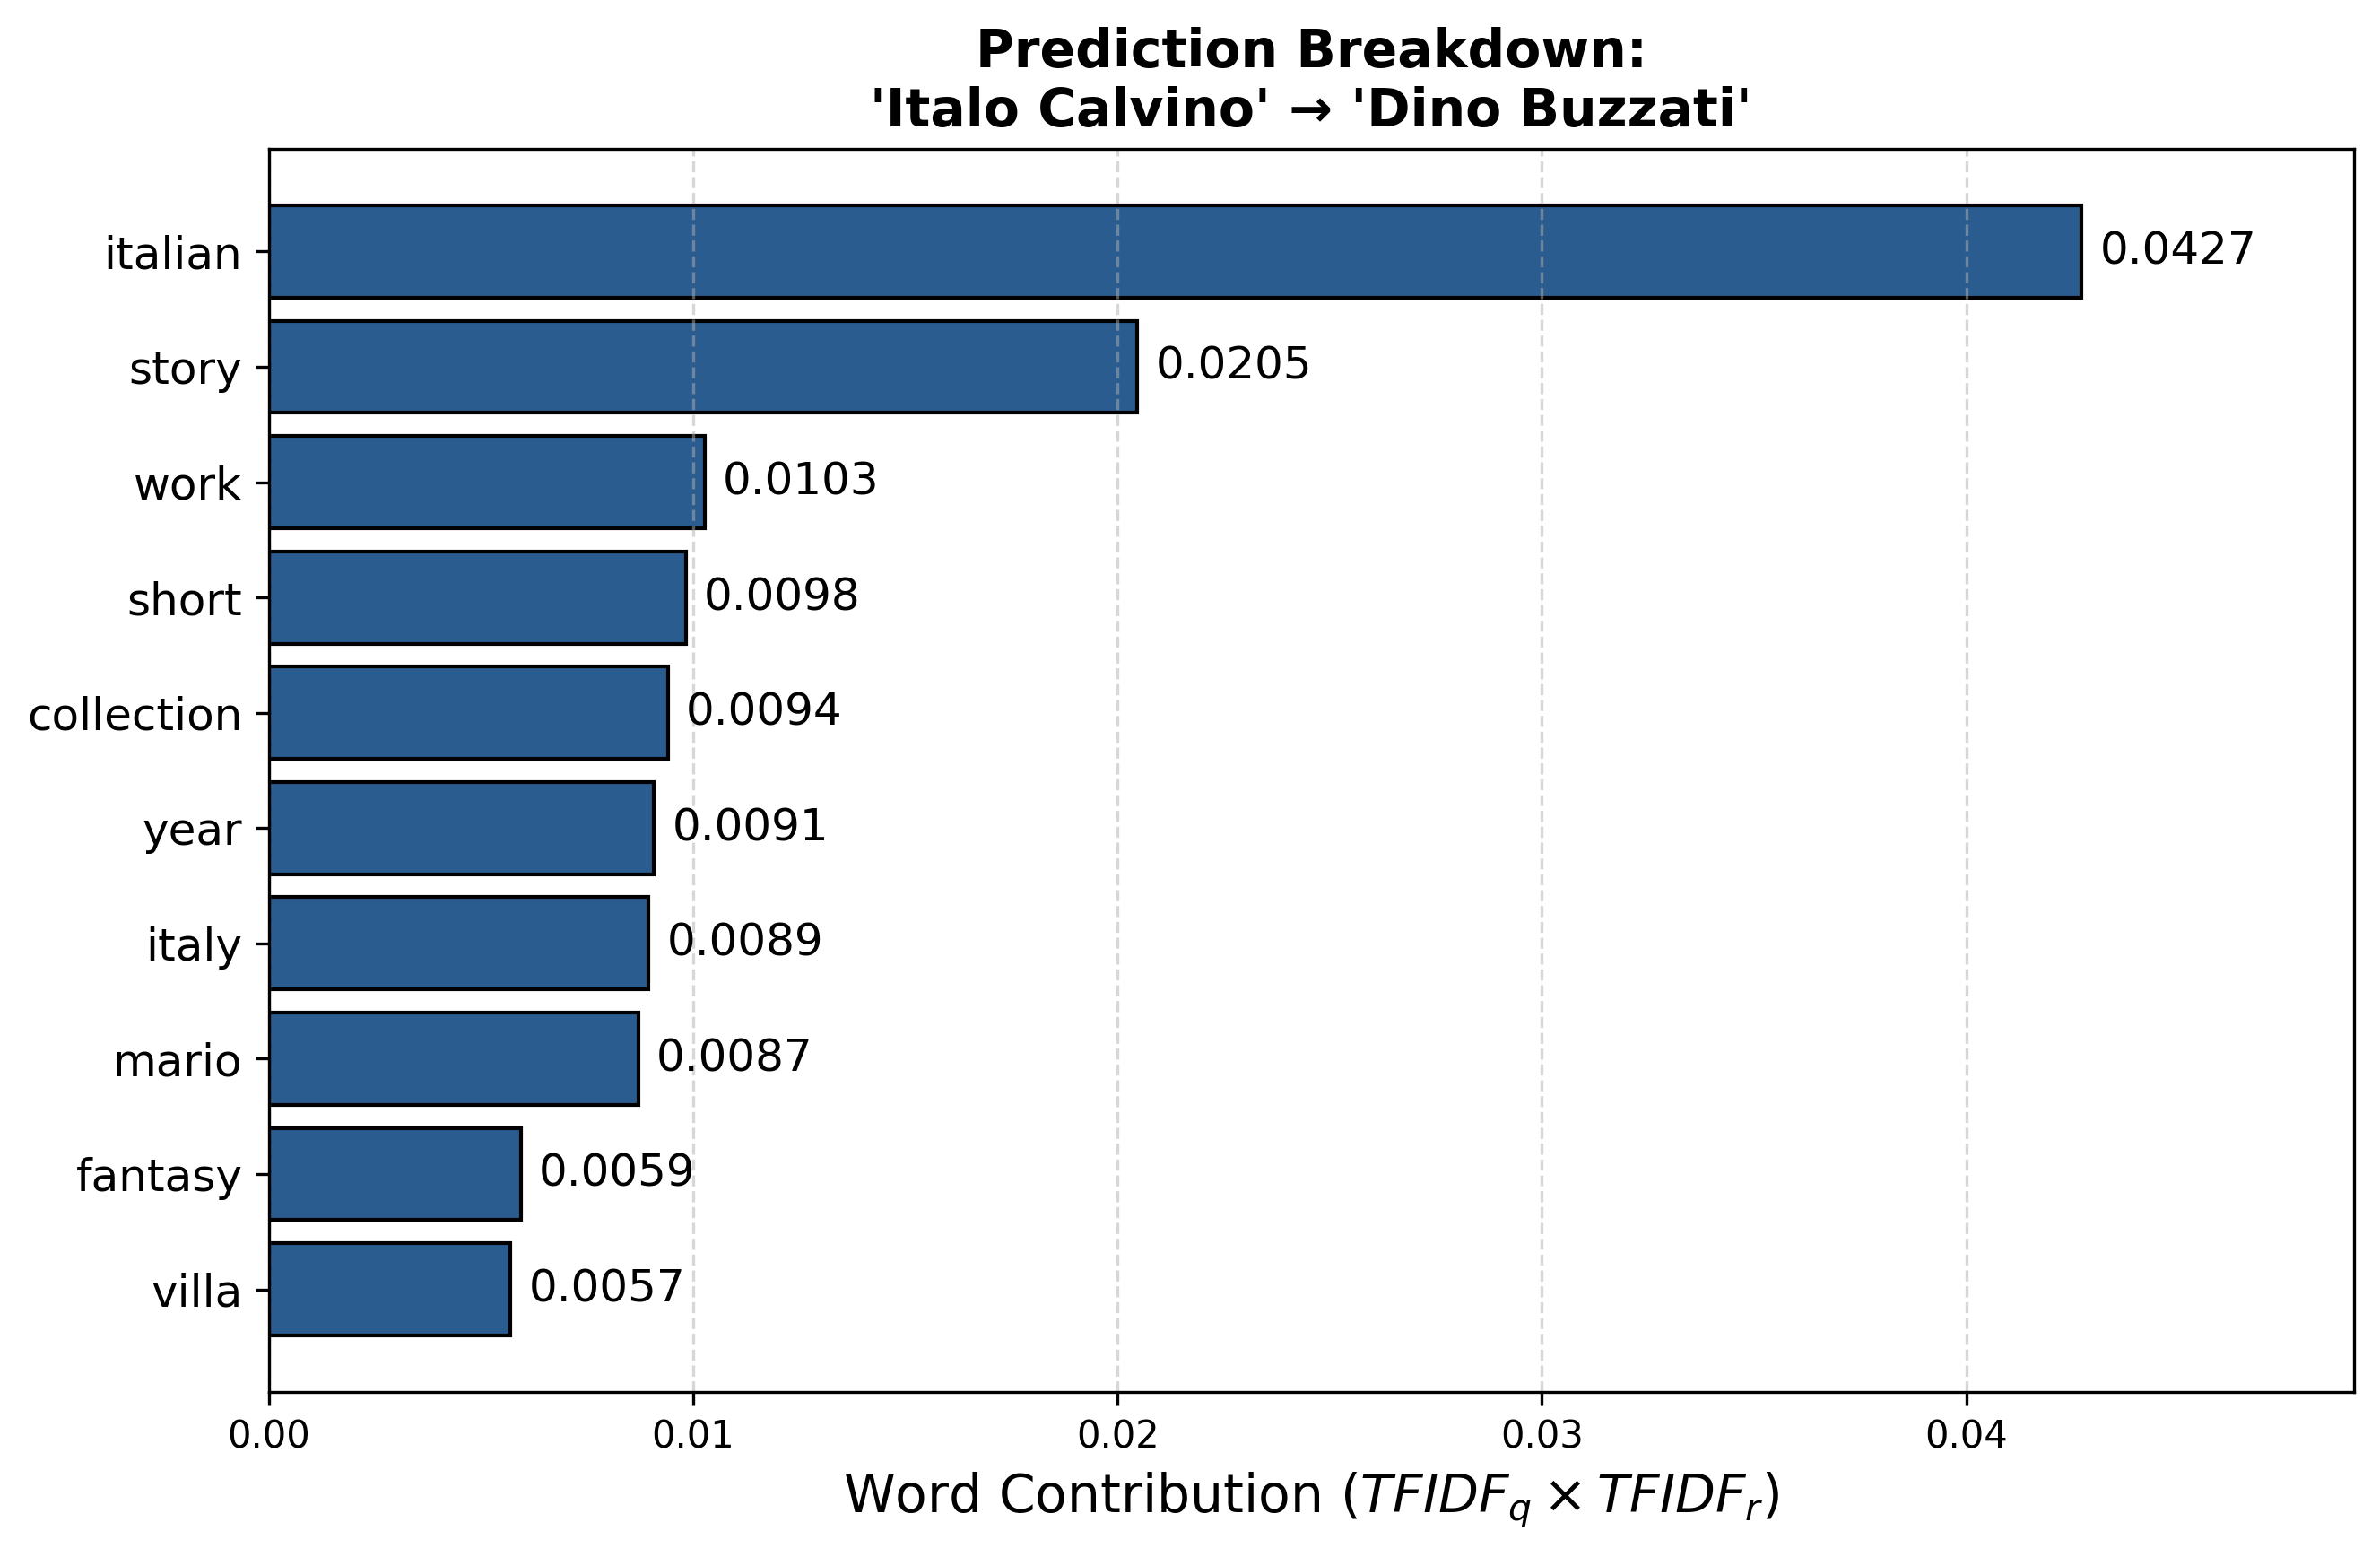

In [ ]:
visualizer.plot_prediction_breakdown(
    query_url="https://en.wikipedia.org/wiki/Italo_Calvino",
    recommendation_url="https://en.wikipedia.org/wiki/Dino_Buzzati",
)

**example:**
When querying Italo Calvino, the system retrieves Dino Buzzati

In [ ]:
recs_1 = recommender.recommend_articles(["https://en.wikipedia.org/wiki/Italo_Calvino"], top_k=1, method="hybrid")
display(recs_1[["title", "final_score", 'dense_score', 'tfidf_score', "url"]])

,title,final_score,dense_score,tfidf_score,url
434,Dino Buzzati,0.946651,0.457846,0.300448,https://en.wikipedia.org/wiki/Dino_Buzzati


The lexical score is driven by shared cultural and stylistic vocabulary: 'italian', 'story', 'work', 'short', 'collection', and 'fantasy'.
The system grounds the recommendation in both geographical origin and shared literary formats

### **Score Component Decomposition:**

To analyze the interaction between semantic understanding and keyword matching, component scores were broken down across top recommendations

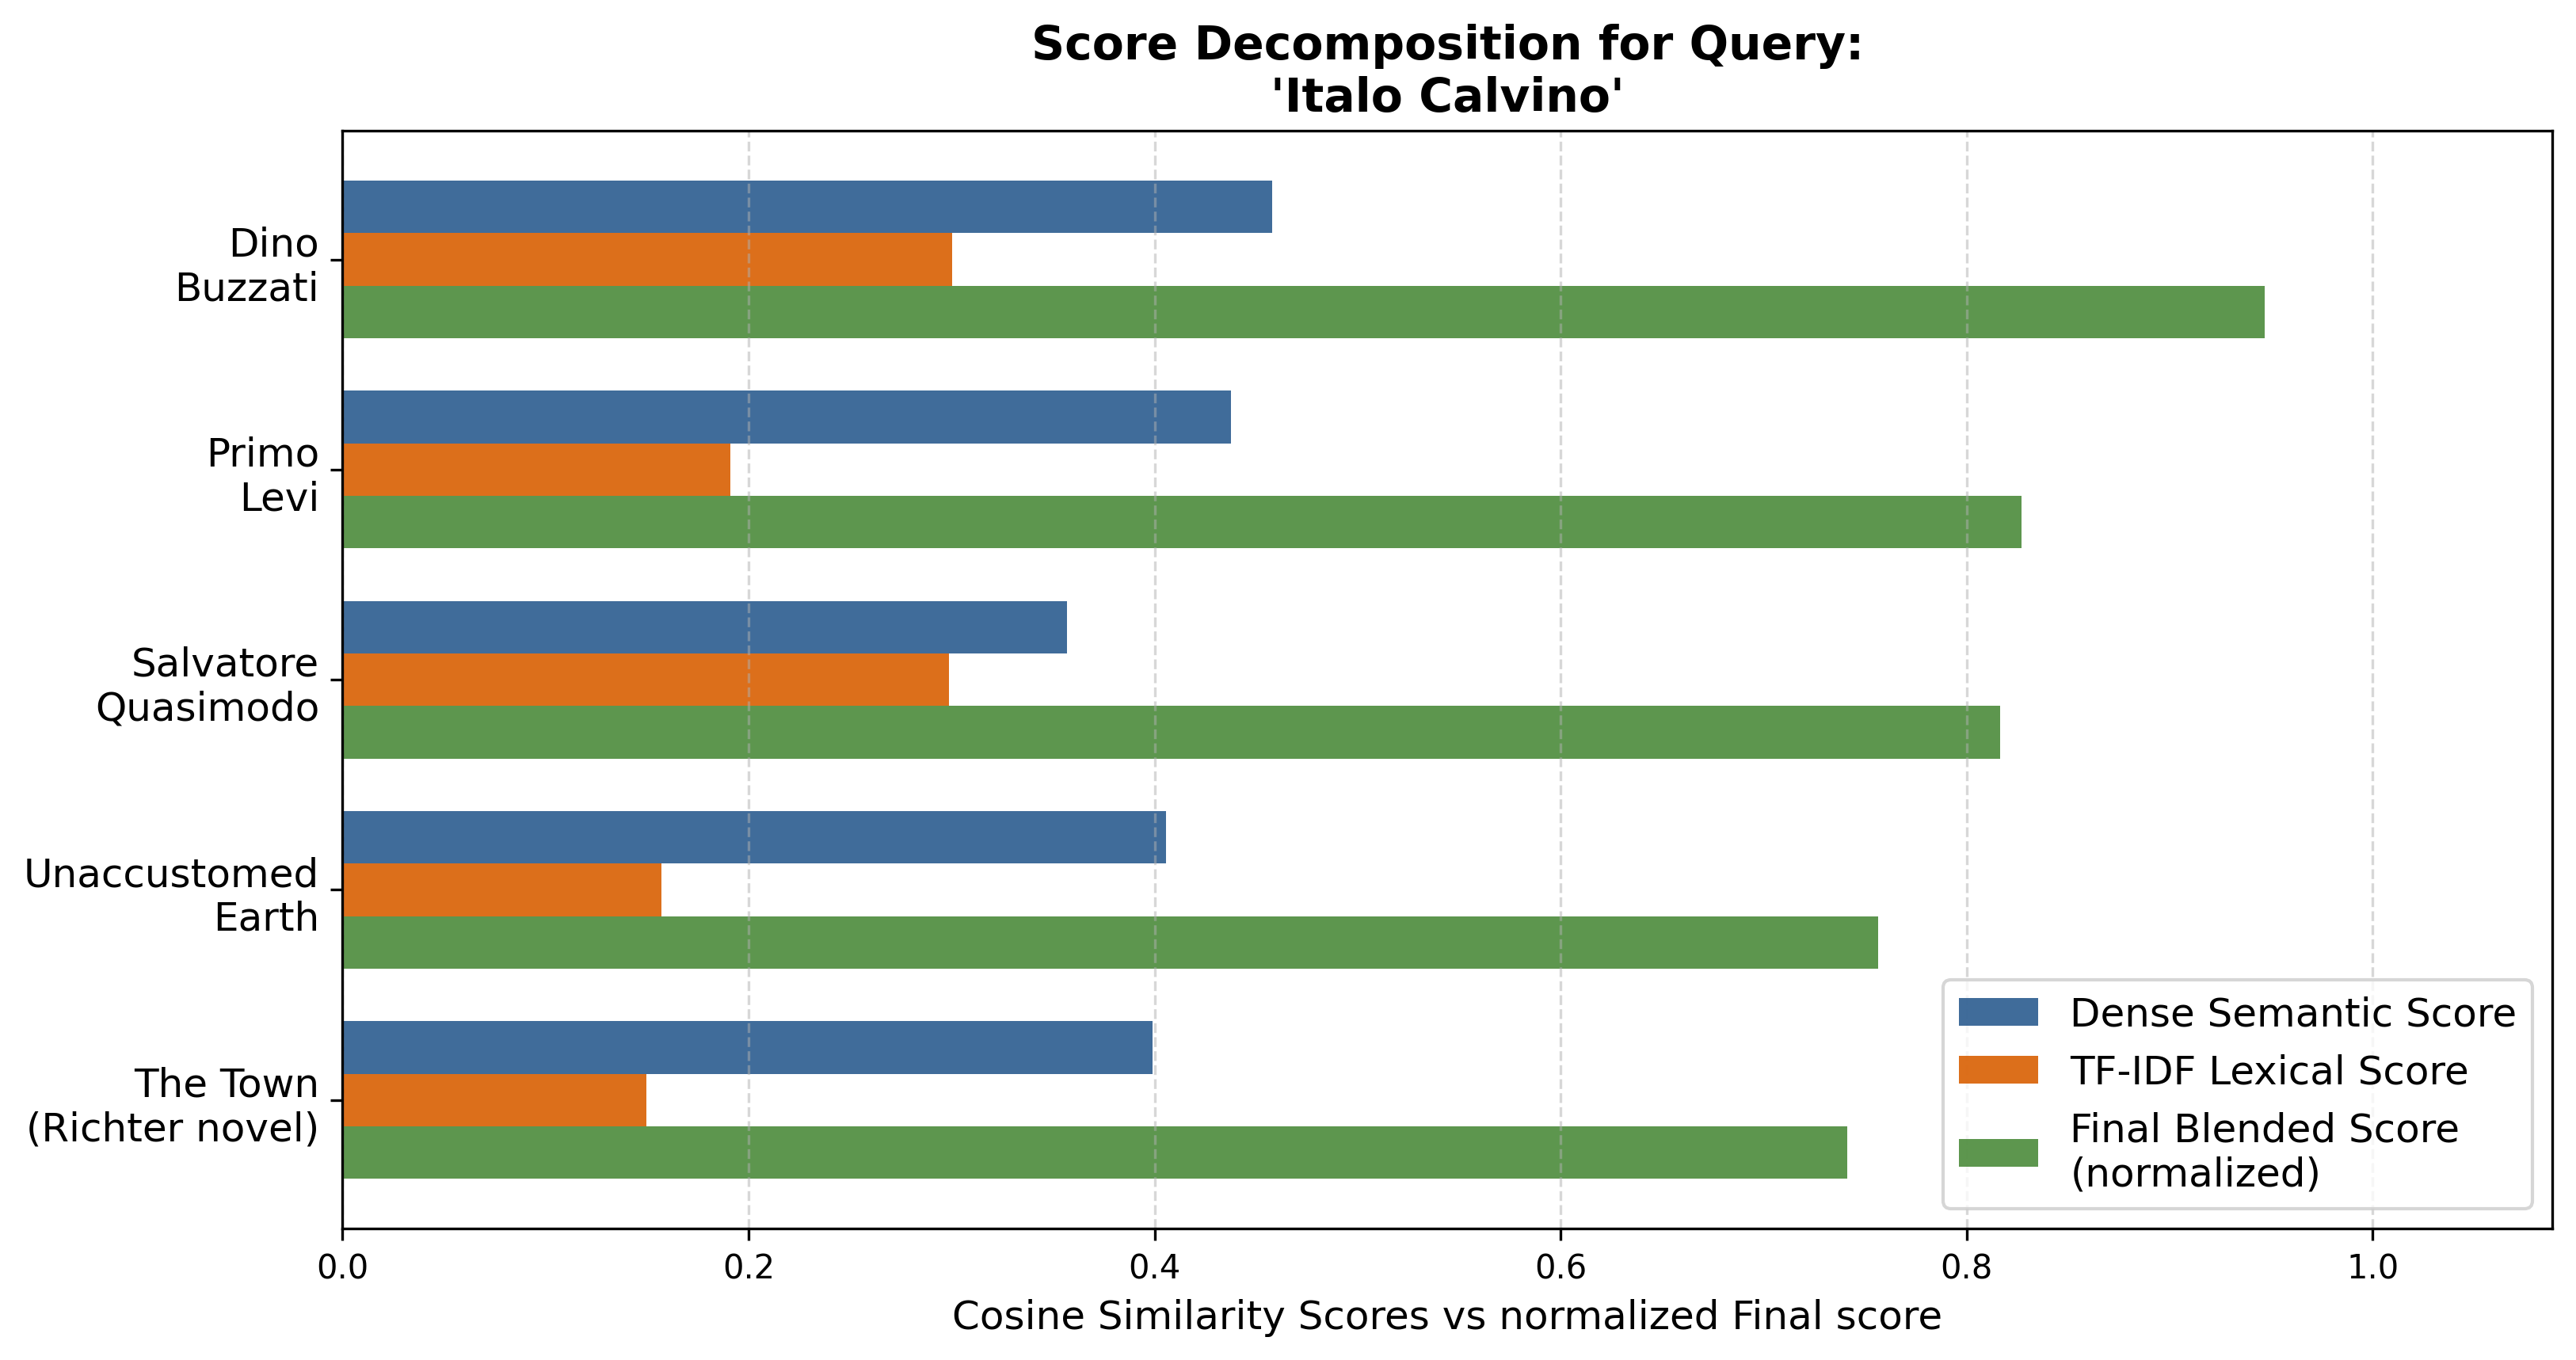

In [ ]:
visualizer.plot_score_decomposition("https://en.wikipedia.org/wiki/Italo_Calvino")

**example:**
The top recommendations for Italo Calvino are dominated by 20th-century Italian authors: Dino Buzzati, Primo Levi, and Salvatore Quasimodo

In [ ]:
recs_2 = recommender.recommend_articles(["https://en.wikipedia.org/wiki/Italo_Calvino"], top_k=5, method="hybrid")
display(recs_2[["title", "final_score", 'dense_score', 'tfidf_score', "url"]])

,title,final_score,dense_score,tfidf_score,url
434,Dino Buzzati,0.946651,0.457846,0.300448,https://en.wikipedia.org/wiki/Dino_Buzzati
47,Primo Levi,0.826866,0.437810,0.191217,https://en.wikipedia.org/wiki/Primo_Levi
179,Salvatore Quasimodo,0.816575,0.356746,0.298861,https://en.wikipedia.org/wiki/Salvatore_Quasimodo
971,Unaccustomed Earth,0.756360,0.405557,0.157100,https://en.wikipedia.org/wiki/Unaccustomed_Earth
405,The Town (Richter novel),0.741289,0.398845,0.149539,https://en.wikipedia.org/wiki/The_Town_(Richte...


Dense semantic scores remain steady ($\sim 0.38 - 0.46$) across the top candidates.
The final ranking order is decided by TF-IDF lexical overlap.
Dino Buzzati takes first place due to a higher TF-IDF score ($0.30$) driven by shared fantasy and short-story terminology.

### **Multi-Article Profile Attribution:**

When a user provides a composite reading profile with multiple genres or philosophies, individual source influence on a recommended item $r$ is evaluated via component similarity:
$$\text{Influence}(a_i, r) = \hat{v}_{a_i} \cdot \hat{v}_r$$

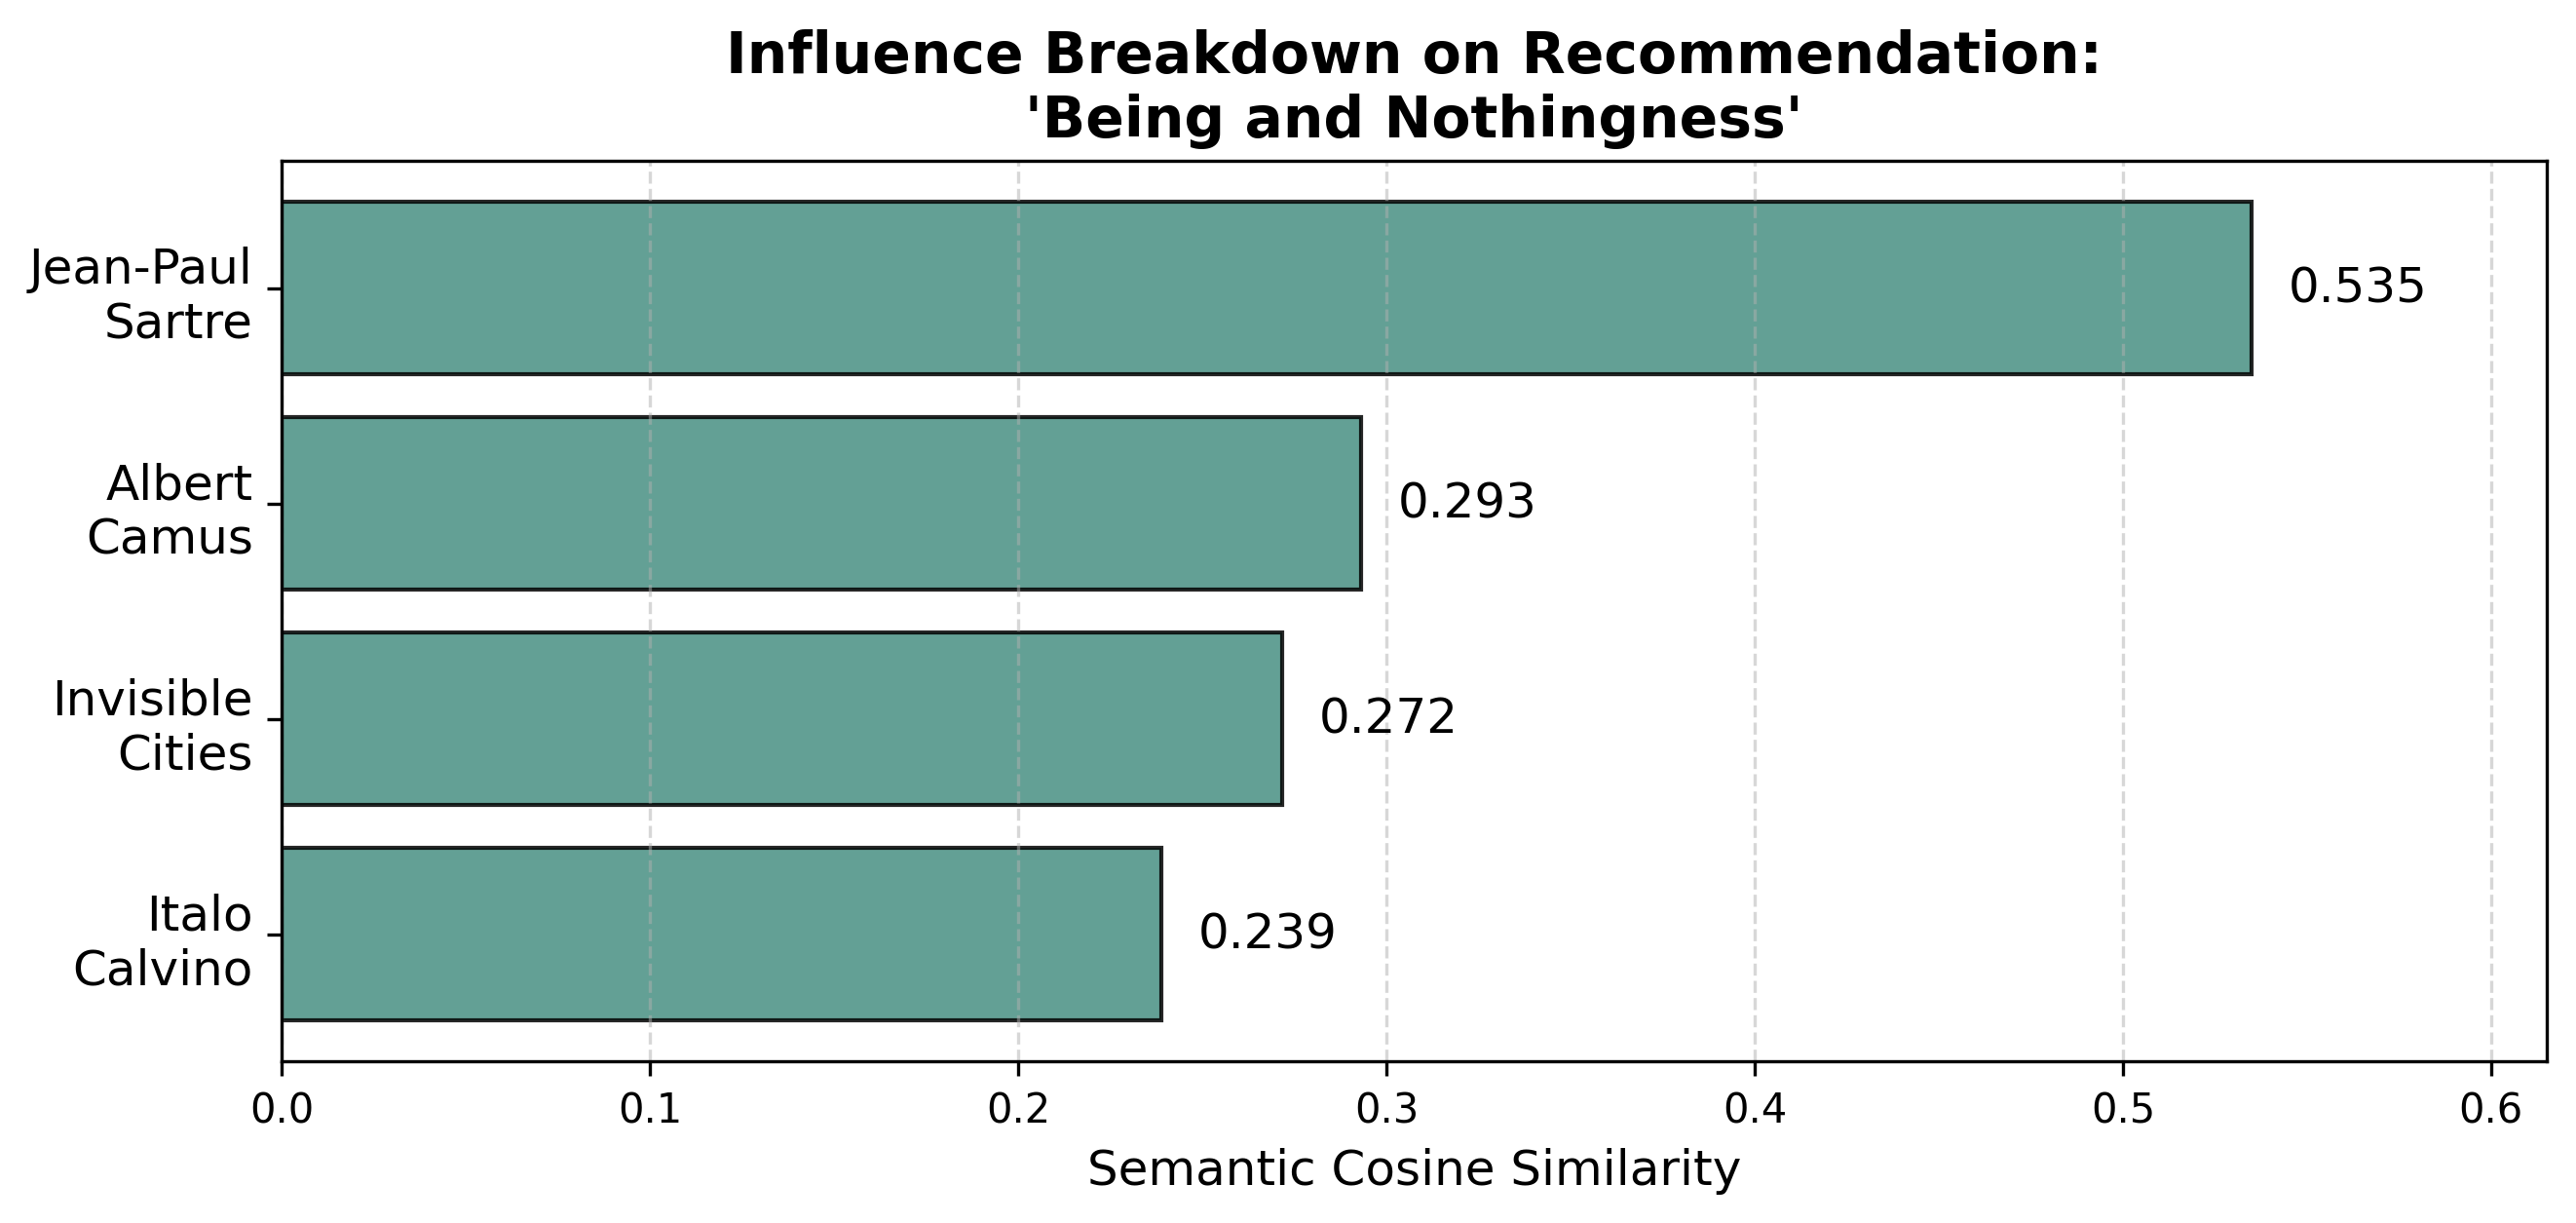

In [ ]:
visited = [
    "https://en.wikipedia.org/wiki/Jean-Paul_Sartre",
    "https://en.wikipedia.org/wiki/Albert_Camus",
    "https://en.wikipedia.org/wiki/Italo_Calvino",
    "https://en.wikipedia.org/wiki/Invisible_Cities",
]
visualizer.plot_user_profile_attribution(visited, "https://en.wikipedia.org/wiki/Being_and_Nothingness")

**example:**
In a mixed profile containing French existentialists (Sartre, Camus) and Italian speculative fiction (Calvino, Invisible Cities), the system recommends Sartre's philosophical work Being and Nothingness.

In [ ]:
recs_3 = recommender.recommend_articles(visited, top_k=3, method="hybrid")
display(recs_3[["title", "final_score", 'dense_score', 'tfidf_score', "url"]])

,title,final_score,dense_score,tfidf_score,url
170,Being and Nothingness,0.673196,0.474943,0.380840,https://en.wikipedia.org/wiki/Being_and_Nothin...
179,Salvatore Quasimodo,0.639533,0.527594,0.225739,https://en.wikipedia.org/wiki/Salvatore_Quasimodo
422,The Rebel (book),0.634865,0.404274,0.430716,https://en.wikipedia.org/wiki/The_Rebel_(book)


Jean-Paul Sartre exerts primary influence ($0.535$). Albert Camus provides secondary reinforcement ($0.293$) due to shared existentialist vocabulary and historical context.
Invisible Cities ($0.272$) and Italo Calvino ($0.239$) remain near baseline.